# FCC-ee Z: final-doublet cryostat motion, IP offsets of beam 1, beam 2 and their difference

Vertical motion of the final doublets (QF1 and QD0) of the four collision IPs (A, D, G, J), using the LCC 108 lattices of beam 1 (e+) and beam 2 (e-).

**Motion model (same as the ground-motion seed study).** Each cryostat moves rigidly with
$d_g(\theta) = \sqrt{2}\,A\cos(\theta + \varphi_g)$, with $A$ the RMS amplitude and $\varphi_g$ a random phase.

* **QF1 cryostat** = QF1a, b, c, d of one side of one IP: one common displacement.
* **QD0 cryostat** = QD0a, b, c of one side of one IP: one common displacement, with its own phase, so it does **not** move in phase with QF1.
* Only magnets of the same cryostat move together. There are 4 IPs x 2 sides x 2 types = **16 cryostats** per ring.
* The two beams share the magnets. A physical cryostat gets the same displacement in the b1 and b2 lattices. The b2 magnet names are counted along the b2 direction, so b2 `...l` is physically the same side as b1 `...r`. The mapping is built from position relative to the IP marker, and the figure in section 3 checks it.

**Observables.** At each IP marker: $\Delta y_{b1}$, $\Delta y_{b2}$ (offset w.r.t. the unperturbed closed orbit, i.e. the IP centre) and $\Delta y_{b1}-\Delta y_{b2}$ (relative offset of the two beams).

**Cases.**
1. `one_side_L` / `one_side_R`: only the QF1 and QD0 cryostats of one side of one IP move (2 cryostats).
2. `both_sides`: all 4 cryostats of one IP move, each with its own random phase.
3. `all_doublets`: all 16 cryostats of the machine move, each with its own random phase.

**Method.** The closed orbit is linear in the shifts at the nm level, so I compute the 4x16 response matrix $R_{\rm beam}$ (y at IP per unit cryostat shift) once with Twiss, check it against a direct Twiss of random configurations, and then evaluate any number of seeds analytically. The RMS over the temporal phase is $A\,|\sum_g R_g e^{i\varphi_g}|$.

In [1]:
from pathlib import Path
import re, shlex, sysconfig
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

for key in ('LDSHARED', 'BLDSHARED', 'LDFLAGS'):
    value = sysconfig.get_config_var(key)
    if value:
        sysconfig.get_config_vars()[key] = ' '.join(dict.fromkeys(shlex.split(value)))
import xtrack as xt

%matplotlib inline
plt.rcParams.update({
    'font.family': 'serif', 'mathtext.fontset': 'stix', 'font.size': 13,
    'axes.labelsize': 14, 'axes.titlesize': 14, 'legend.fontsize': 10,
    'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True,
    'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
})

## 1. Configuration

In [2]:
LATTICE_DIR = Path('/Users/skostogl/Documents/workspace/workspace_2026/FCC/10_2026/tapering/acc-models-fcc-ee/108/acc-models-fcc-ee/lattices/z')
LINE_FILES = {'b1': LATTICE_DIR/'fccee_z_beam_1_positrons.json', 'b2': LATTICE_DIR/'fccee_z_beam_2_electrons.json'}
OUTPUT_DIR = Path('results'); FIGURE_DIR = OUTPUT_DIR/'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

IP_NAMES = ('ipa', 'ipd', 'ipg', 'ipj')     # physical collision IPs (names are the same in both lattices)
GEMITT_Y_M = 2.419172e-12                   # parameter_table.txt of the LCC 108 Z lattice
A_REF_NM = 10.0                             # RMS amplitude per cryostat used for the headline numbers
N_SEEDS = 2000
PROBE_SHIFT_M = 10e-9                       # +-shift for the central-difference response (orbit is not linear at ~1 um: sextupole feed-down)
DOUBLET_WINDOW_M = 20.0                     # doublet magnets are searched within +-20 m of the IP marker

## 2. Load both rings and define the cryostats

In [3]:
MAGNET_RE = re.compile(r'^(qd0|qf1)([a-d])([lr])(\.\d+)?$')

lines, tables = {}, {}
for beam, path in LINE_FILES.items():
    env = xt.Environment.from_json(path)
    line = env[list(env.lines)[0]]
    line.configure_radiation(model=None)
    lines[beam] = line
    tables[beam] = line.get_table()

def doublet_cryostats(beam):
    """name -> (ip, physical side, 'QF1'|'QD0'), built from the position relative to the IP marker.

    b1 runs towards +z, so its downstream side is the physical right (R). b2 runs the other way,
    so its downstream side is the physical left (L).
    """
    table = tables[beam]
    names = np.asarray(table.name, dtype=str); s = np.asarray(table.s, dtype=float)
    circumference = s[-1]
    ip_s = {ip: float(s[names == ip][0]) for ip in IP_NAMES}
    groups = {}
    for name, s_magnet in zip(names, s):
        match = MAGNET_RE.match(name)
        if not match:
            continue
        distance = {ip: (s_magnet - s_ip + circumference/2) % circumference - circumference/2 for ip, s_ip in ip_s.items()}
        ip = min(distance, key=lambda key: abs(distance[key]))
        if abs(distance[ip]) > DOUBLET_WINDOW_M:
            continue
        downstream = distance[ip] > 0
        side = ('R' if downstream else 'L') if beam == 'b1' else ('L' if downstream else 'R')
        groups[name] = (ip, side, 'QD0' if match.group(1) == 'qd0' else 'QF1')
    return groups

CRYOSTATS = [(ip, side, magnet) for ip in IP_NAMES for side in ('L', 'R') for magnet in ('QF1', 'QD0')]
cryostat_members = {beam: {c: [] for c in CRYOSTATS} for beam in lines}
for beam in lines:
    for name, key in doublet_cryostats(beam).items():
        cryostat_members[beam][key].append(name)

rows = [{'beam': beam, 'ip': c[0], 'side': c[1], 'magnet': c[2], 'n_modules': len(cryostat_members[beam][c]),
         'modules': ' '.join(cryostat_members[beam][c])} for beam in lines for c in CRYOSTATS]
membership = pd.DataFrame(rows)
assert (membership.n_modules == membership.magnet.map({'QF1': 4, 'QD0': 3})).all(), 'wrong number of modules in a cryostat'
display(membership[membership.ip == 'ipd'])
print(f'{len(CRYOSTATS)} cryostats per ring; modules per cryostat OK (QF1: 4, QD0: 3)')

Loading line from dict:   0%|          | 0/19884 [00:00<?, ?it/s]

Loading line from dict:   0%|          | 0/19885 [00:00<?, ?it/s]

,beam,ip,side,magnet,n_modules,modules
4,b1,ipd,L,QF1,4,qf1dl.0 qf1cl.0 qf1bl.0 qf1al.0
5,b1,ipd,L,QD0,3,qd0cl.0 qd0bl.0 qd0al.0
6,b1,ipd,R,QF1,4,qf1ar.1 qf1br.1 qf1cr.1 qf1dr.1
7,b1,ipd,R,QD0,3,qd0ar.1 qd0br.1 qd0cr.1
20,b2,ipd,L,QF1,4,qf1ar.3 qf1br.3 qf1cr.3 qf1dr.3
21,b2,ipd,L,QD0,3,qd0ar.3 qd0br.3 qd0cr.3
22,b2,ipd,R,QF1,4,qf1dl.2 qf1cl.2 qf1bl.2 qf1al.2
23,b2,ipd,R,QD0,3,qd0cl.2 qd0bl.2 qd0al.2


16 cryostats per ring; modules per cryostat OK (QF1: 4, QD0: 3)


## 3. Check of the cryostat definition (IP A)

Positions are shown in the physical frame (right = +z). The b1 and b2 rows must show the same magnets in the same places, and every cryostat has one colour.

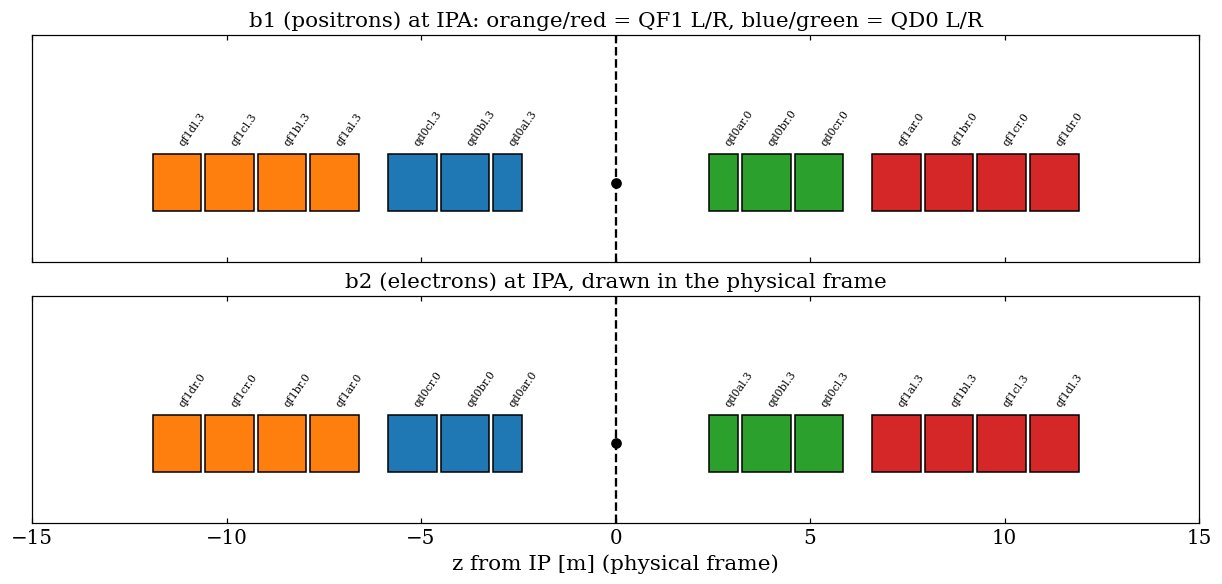

In [4]:
def draw_doublet(ax, beam, ip='ipa', title=''):
    table = tables[beam]
    names = np.asarray(table.name, dtype=str); s = np.asarray(table.s, dtype=float)
    circumference = s[-1]; s_ip = float(s[names == ip][0])
    quad_length = {n: float(getattr(lines[beam][n], 'length')) for n in names if MAGNET_RE.match(n)}
    colors = {'QF1': ('tab:orange', 'tab:red'), 'QD0': ('tab:blue', 'tab:green')}
    for name, (ip_g, side, magnet) in doublet_cryostats(beam).items():
        if ip_g != ip:
            continue
        s_entry = float(s[names == name][0])
        d0 = (s_entry - s_ip + circumference/2) % circumference - circumference/2
        d1 = d0 + quad_length[name]
        lo, hi = (d0, d1) if beam == 'b1' else (-d1, -d0)
        ax.add_patch(plt.Rectangle((lo, -0.5), hi - lo, 1.0, facecolor=colors[magnet][side == 'R'], edgecolor='k'))
        ax.text((lo + hi)/2, 0.62, name, rotation=55, ha='left', va='bottom', fontsize=7)
    ax.axvline(0, color='k', ls='--'); ax.plot(0, 0, 'ko')
    ax.set_xlim(-15, 15); ax.set_ylim(-1.4, 2.6); ax.set_yticks([]); ax.set_title(title)

fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True, layout='constrained')
draw_doublet(axes[0], 'b1', title='b1 (positrons) at IPA: orange/red = QF1 L/R, blue/green = QD0 L/R')
draw_doublet(axes[1], 'b2', title='b2 (electrons) at IPA, drawn in the physical frame')
axes[1].set_xlabel('z from IP [m] (physical frame)')
fig.savefig(FIGURE_DIR/'cryostat_definition_ipa.png'); plt.show()

## 4. Reference orbit and IP beam sizes

In [5]:
twiss_reference = {beam: lines[beam].twiss(method='4d') for beam in lines}
y_reference = {beam: np.asarray(twiss_reference[beam].rows[list(IP_NAMES)].y, float) for beam in lines}
bety_ip = {beam: np.asarray(twiss_reference[beam].rows[list(IP_NAMES)].bety, float) for beam in lines}
sigma_y_m = {beam: np.sqrt(GEMITT_Y_M*bety_ip[beam]) for beam in lines}
sigma_y_diff_m = 0.5*(sigma_y_m['b1'] + sigma_y_m['b2'])
print('reference y at IPs [m]:', {b: y_reference[b] for b in lines})
display(pd.DataFrame({'ip': IP_NAMES, 'bety_b1_mm': 1e3*bety_ip['b1'], 'bety_b2_mm': 1e3*bety_ip['b2'],
                      'sigma_y_b1_nm': 1e9*sigma_y_m['b1'], 'sigma_y_b2_nm': 1e9*sigma_y_m['b2']}))

reference y at IPs [m]: {'b1': array([0.00000000e+00, 2.03105831e-26, 5.89900930e-26, 1.31736647e-25]), 'b2': array([ 0.00000000e+00, -1.26916404e-25,  1.18791027e-27, -1.39554105e-25])}


,ip,bety_b1_mm,bety_b2_mm,sigma_y_b1_nm,sigma_y_b2_nm
0,ipa,0.799756,0.799717,43.985759,43.984690
1,ipd,0.799747,0.799725,43.985526,43.984919
2,ipg,0.799723,0.799744,43.984867,43.985437
3,ipj,0.799711,0.799764,43.984513,43.985995


## 5. Response matrix

$R_{\rm beam}[i, g]$ = change of $y$ at IP $i$ for a unit vertical shift of cryostat $g$ (all its modules together), in m/m.

In [6]:
def ip_offsets(beam):
    twiss = lines[beam].twiss(method='4d')
    return np.asarray(twiss.rows[list(IP_NAMES)].y, float) - y_reference[beam]

def set_shift(beam, cryostat, value):
    for name in cryostat_members[beam][cryostat]:
        lines[beam][name].shift_y = value

response = {beam: np.zeros((len(IP_NAMES), len(CRYOSTATS))) for beam in lines}
for beam in lines:
    for g, cryostat in enumerate(CRYOSTATS):
        set_shift(beam, cryostat, +PROBE_SHIFT_M); plus = ip_offsets(beam)
        set_shift(beam, cryostat, -PROBE_SHIFT_M); minus = ip_offsets(beam)
        set_shift(beam, cryostat, 0.0)
        response[beam][:, g] = (plus - minus)/(2*PROBE_SHIFT_M)

labels = [f'{ip}-{side}-{magnet}' for ip, side, magnet in CRYOSTATS]
response_table = pd.concat({beam: pd.DataFrame(response[beam], index=IP_NAMES, columns=labels) for beam in lines})
response_table.to_csv(OUTPUT_DIR/'response_matrix_m_per_m.csv')
own = pd.DataFrame([{'beam': beam, 'ip': ip, 'cryostat': f'{side}-{magnet}', 'dy_ip / dy_cryostat': response[beam][i, g]}
                    for beam in lines for i, ip in enumerate(IP_NAMES) for g, (ip_g, side, magnet) in enumerate(CRYOSTATS) if ip_g == ip])
display(own.pivot_table(index=['beam', 'ip'], columns='cryostat', values='dy_ip / dy_cryostat').round(2))
print('largest response from a cryostat of a different IP (remote effect):',
      max(abs(response[b][i, g]) for b in lines for i, ip in enumerate(IP_NAMES) for g, c in enumerate(CRYOSTATS) if c[0] != ip))

cryostat  L-QD0  L-QF1  R-QD0  R-QF1
beam ip                             
b1   ipa   0.74  -0.24   0.75  -0.24
     ipd   0.74  -0.24   0.75  -0.24
     ipg   0.74  -0.24   0.75  -0.24
     ipj   0.74  -0.24   0.75  -0.24
b2   ipa   0.75  -0.24   0.74  -0.24
     ipd   0.75  -0.24   0.74  -0.24
     ipg   0.75  -0.24   0.74  -0.24
     ipj   0.75  -0.24   0.74  -0.24

largest response from a cryostat of a different IP (remote effect): 0.3931678734263416


## 6. Check of the linear model against a direct Twiss

Random phases on all 16 cryostats, applied to both rings, with a direct closed-orbit Twiss for a few seeds, temporal phases and amplitudes.

In [7]:
def random_phases(seed):
    return np.random.default_rng(seed).uniform(0.0, 2*np.pi, len(CRYOSTATS))

check_rows = []
for seed, theta, amplitude_nm in [(1, 0.0, 10.0), (2, 1.3, 10.0), (3, 4.0, 50.0), (4, 2.2, 200.0)]:
    shifts = np.sqrt(2.0)*amplitude_nm*1e-9*np.cos(theta + random_phases(seed))
    for beam in lines:
        for cryostat, value in zip(CRYOSTATS, shifts):
            set_shift(beam, cryostat, value)
    direct = {beam: ip_offsets(beam) for beam in lines}
    for beam in lines:
        for cryostat in CRYOSTATS:
            set_shift(beam, cryostat, 0.0)
    for beam in lines:
        linear = response[beam] @ shifts
        check_rows.append({'seed': seed, 'A_rms_nm': amplitude_nm, 'beam': beam,
                           'max |direct| [nm]': 1e9*np.max(np.abs(direct[beam])),
                           'max |direct-linear| [nm]': 1e9*np.max(np.abs(direct[beam] - linear))})
check = pd.DataFrame(check_rows)
display(check)
assert (check['max |direct-linear| [nm]'] < 0.01*check['max |direct| [nm]']).all()

,seed,A_rms_nm,beam,max |direct| [nm],max |direct-linear| [nm]
0,1,10.0,b1,15.684770,0.000101
1,1,10.0,b2,15.689865,0.000092
2,2,10.0,b1,19.722242,0.000030
3,2,10.0,b2,19.841757,0.000029
4,3,50.0,b1,77.362185,0.007310
5,3,50.0,b2,77.793048,0.007742
6,4,200.0,b1,481.454334,0.037395
7,4,200.0,b2,479.220211,0.042744


## 7. Cases and statistics over random phases

For each seed one phase per cryostat is drawn. The same phases are reused in every case, so the cases are nested. For a case with active cryostats $g$ the RMS over the temporal phase is $A\,|\sum_g R_g e^{i\varphi_g}|$ for each beam, and $A\,|\sum_g (R_{b1,g}-R_{b2,g})\,e^{i\varphi_g}|$ for the relative offset.

In [8]:
CASES = [('one_side_L', ip) for ip in IP_NAMES] + [('one_side_R', ip) for ip in IP_NAMES] + \
        [('both_sides', ip) for ip in IP_NAMES] + [('all_doublets', None)]

def active_mask(case, moved_ip):
    if case == 'all_doublets':
        return np.ones(len(CRYOSTATS), bool)
    if case == 'both_sides':
        return np.array([c[0] == moved_ip for c in CRYOSTATS])
    side = case[-1]
    return np.array([c[0] == moved_ip and c[1] == side for c in CRYOSTATS])

seeds = np.arange(N_SEEDS)
phasors = np.exp(1j*np.array([random_phases(seed) for seed in seeds]))        # (seeds, cryostats)
R1, R2 = response['b1'], response['b2']

records = []
for case, moved_ip in CASES:
    mask = active_mask(case, moved_ip)
    for i, ip in enumerate(IP_NAMES):
        rms_b1 = A_REF_NM*np.abs(phasors[:, mask] @ R1[i, mask])
        rms_b2 = A_REF_NM*np.abs(phasors[:, mask] @ R2[i, mask])
        rms_diff = A_REF_NM*np.abs(phasors[:, mask] @ (R1[i, mask] - R2[i, mask]))
        records.append(pd.DataFrame({
            'case': case, 'moved_ip': moved_ip or 'all', 'observed_ip': ip, 'seed': seeds,
            'n_cryostats': int(mask.sum()), 'A_rms_nm': A_REF_NM,
            'b1_rms_nm': rms_b1, 'b2_rms_nm': rms_b2, 'diff_rms_nm': rms_diff,
            'b1_rms_sigma': rms_b1*1e-9/sigma_y_m['b1'][i], 'b2_rms_sigma': rms_b2*1e-9/sigma_y_m['b2'][i],
            'diff_rms_sigma': rms_diff*1e-9/sigma_y_diff_m[i]}))
offsets = pd.concat(records, ignore_index=True)
offsets['local'] = (offsets.moved_ip == offsets.observed_ip) | (offsets.moved_ip == 'all')
offsets.to_csv(OUTPUT_DIR/'ip_offsets_by_seed.csv', index=False)
local = offsets[offsets.local]

def summarise(frame, by):
    rows = []
    for key, group in frame.groupby(by, sort=False):
        row = dict(zip(by, key if isinstance(key, tuple) else (key,)))
        for quantity in ('b1', 'b2', 'diff'):
            values = group[f'{quantity}_rms_nm'].to_numpy()
            row[f'{quantity}_rms_over_seeds_nm'] = float(np.sqrt(np.mean(values**2)))
            row[f'{quantity}_median_nm'] = float(np.median(values))
            row[f'{quantity}_p95_nm'] = float(np.quantile(values, 0.95))
        row['diff_rms_over_seeds_sigma'] = float(np.sqrt(np.mean(group['diff_rms_sigma']**2)))
        row['diff_p95_sigma'] = float(np.quantile(group['diff_rms_sigma'], 0.95))
        rows.append(row)
    return pd.DataFrame(rows)

summary_by_ip = summarise(local, ['case', 'observed_ip'])
summary_by_case = summarise(local.assign(observed_ip='pooled'), ['case', 'observed_ip'])
summary_by_ip.to_csv(OUTPUT_DIR/'summary_by_ip.csv', index=False)
print(f'A = {A_REF_NM:g} nm RMS per cryostat, {N_SEEDS} seeds. Offsets are RMS over the temporal phase.')
print('one_side_L / one_side_R / both_sides: moved IP only. all_doublets: all 16 cryostats move.')
display(summary_by_case.round(3))

A = 10 nm RMS per cryostat, 2000 seeds. Offsets are RMS over the temporal phase.
one_side_L / one_side_R / both_sides: moved IP only. all_doublets: all 16 cryostats move.


,case,observed_ip,b1_rms_over_seeds_nm,b1_median_nm,b1_p95_nm,b2_rms_over_seeds_nm,b2_median_nm,b2_p95_nm,diff_rms_over_seeds_nm,diff_median_nm,diff_p95_nm,diff_rms_over_seeds_sigma,diff_p95_sigma
0,one_side_L,pooled,7.779,7.743,9.790,7.846,7.809,9.880,0.067,0.066,0.089,0.002,0.002
1,one_side_R,pooled,7.822,7.803,9.877,7.756,7.737,9.788,0.067,0.066,0.089,0.002,0.002
2,both_sides,pooled,10.958,10.233,17.300,10.959,10.234,17.295,0.095,0.085,0.154,0.002,0.003
3,all_doublets,pooled,13.784,11.943,23.197,13.784,11.924,23.201,0.118,0.101,0.199,0.003,0.005


### Per-IP table (offset at the IP whose doublet moves)

In [9]:
display(summary_by_ip.round(3))

,case,observed_ip,b1_rms_over_seeds_nm,b1_median_nm,b1_p95_nm,b2_rms_over_seeds_nm,b2_median_nm,b2_p95_nm,diff_rms_over_seeds_nm,diff_median_nm,diff_p95_nm,diff_rms_over_seeds_sigma,diff_p95_sigma
0,one_side_L,ipa,7.737,7.601,9.786,7.802,7.665,9.876,0.067,0.065,0.090,0.002,0.002
1,one_side_L,ipd,7.808,7.798,9.790,7.874,7.864,9.880,0.067,0.067,0.089,0.002,0.002
2,one_side_L,ipg,7.834,7.871,9.794,7.901,7.938,9.883,0.067,0.068,0.089,0.002,0.002
3,one_side_L,ipj,7.739,7.649,9.790,7.805,7.714,9.880,0.067,0.065,0.090,0.002,0.002
4,one_side_R,ipa,7.790,7.782,9.875,7.724,7.716,9.785,0.066,0.066,0.090,0.002,0.002
5,one_side_R,ipd,7.844,7.831,9.883,7.778,7.766,9.794,0.067,0.067,0.089,0.002,0.002
6,one_side_R,ipg,7.834,7.828,9.877,7.768,7.762,9.788,0.067,0.066,0.089,0.002,0.002
7,one_side_R,ipj,7.819,7.782,9.875,7.753,7.717,9.785,0.067,0.066,0.089,0.002,0.002
8,both_sides,ipa,10.984,10.418,17.367,10.985,10.428,17.364,0.094,0.084,0.151,0.002,0.003
9,both_sides,ipd,11.042,10.243,17.339,11.043,10.239,17.324,0.095,0.085,0.152,0.002,0.003


### Remote effect: offset at an IP produced by motion of the doublets of the other IPs

In [10]:
remote = offsets[(~offsets.local) & (offsets.case == 'both_sides')]
display(summarise(remote.assign(observed_ip='other IPs'), ['case', 'observed_ip']).round(3))

,case,observed_ip,b1_rms_over_seeds_nm,b1_median_nm,b1_p95_nm,b2_rms_over_seeds_nm,b2_median_nm,b2_p95_nm,diff_rms_over_seeds_nm,diff_median_nm,diff_p95_nm,diff_rms_over_seeds_sigma,diff_p95_sigma
0,both_sides,other IPs,4.766,3.219,8.706,4.766,3.21,8.703,0.041,0.028,0.078,0.001,0.002


## 8. Plots

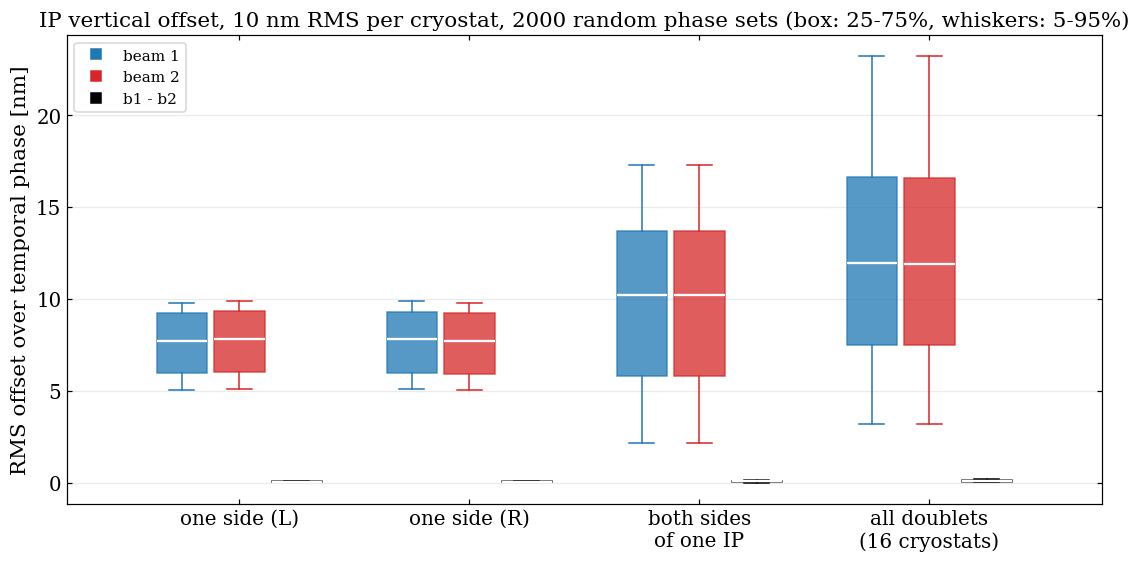

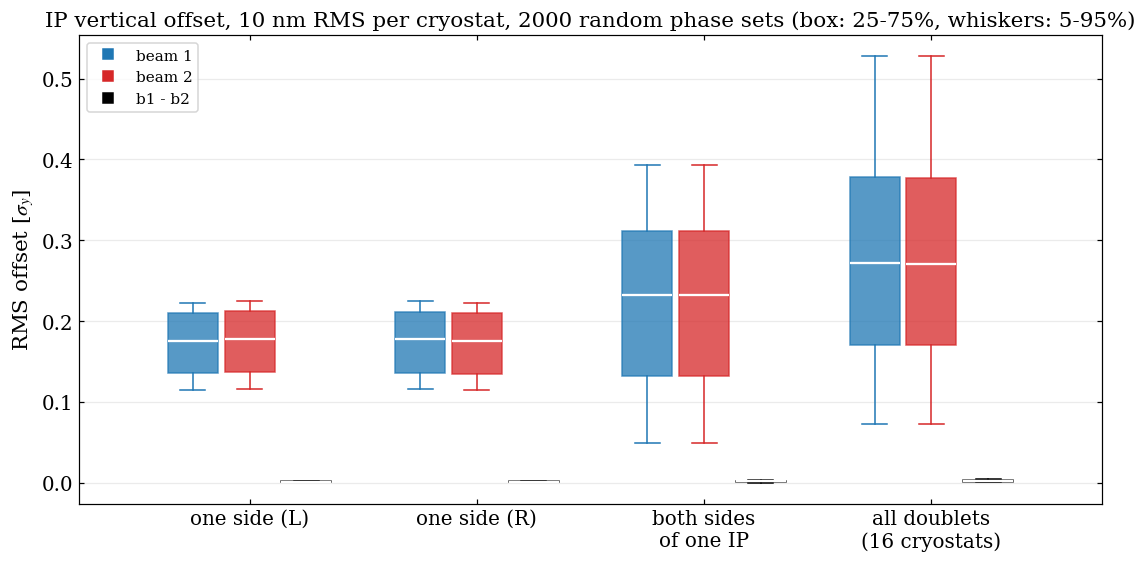

In [11]:
CASE_LABELS = {'one_side_L': 'one side (L)', 'one_side_R': 'one side (R)', 'both_sides': 'both sides\nof one IP', 'all_doublets': 'all doublets\n(16 cryostats)'}
QUANTITIES = (('b1', 'beam 1', 'tab:blue'), ('b2', 'beam 2', 'tab:red'), ('diff', 'b1 - b2', 'black'))

def boxplot_by_case(column_suffix, ylabel, filename, title):
    fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
    cases = list(CASE_LABELS)
    width = 0.25
    for k, (quantity, label, color) in enumerate(QUANTITIES):
        data = [local[local.case == case][f'{quantity}_{column_suffix}'].to_numpy() for case in cases]
        positions = np.arange(len(cases)) + (k - 1)*width
        bp = ax.boxplot(data, positions=positions, widths=0.22, patch_artist=True, showfliers=False, whis=(5, 95),
                        medianprops=dict(color='white', lw=1.5))
        for box in bp['boxes']:
            box.set(facecolor=color, alpha=0.75, edgecolor=color)
        for item in bp['whiskers'] + bp['caps']:
            item.set(color=color)
        ax.plot([], [], 's', color=color, label=label)
    ax.set_xticks(np.arange(len(cases)), [CASE_LABELS[c] for c in cases])
    ax.set_ylabel(ylabel); ax.set_title(title); ax.grid(axis='y', alpha=0.25); ax.legend(loc='upper left')
    fig.savefig(FIGURE_DIR/filename); plt.show()

title = f'IP vertical offset, {A_REF_NM:g} nm RMS per cryostat, {N_SEEDS} random phase sets (box: 25-75%, whiskers: 5-95%)'
boxplot_by_case('rms_nm', r'RMS offset over temporal phase [nm]', 'offset_by_case_nm.png', title)
boxplot_by_case('rms_sigma', r'RMS offset [$\sigma_y$]', 'offset_by_case_sigma.png', title)

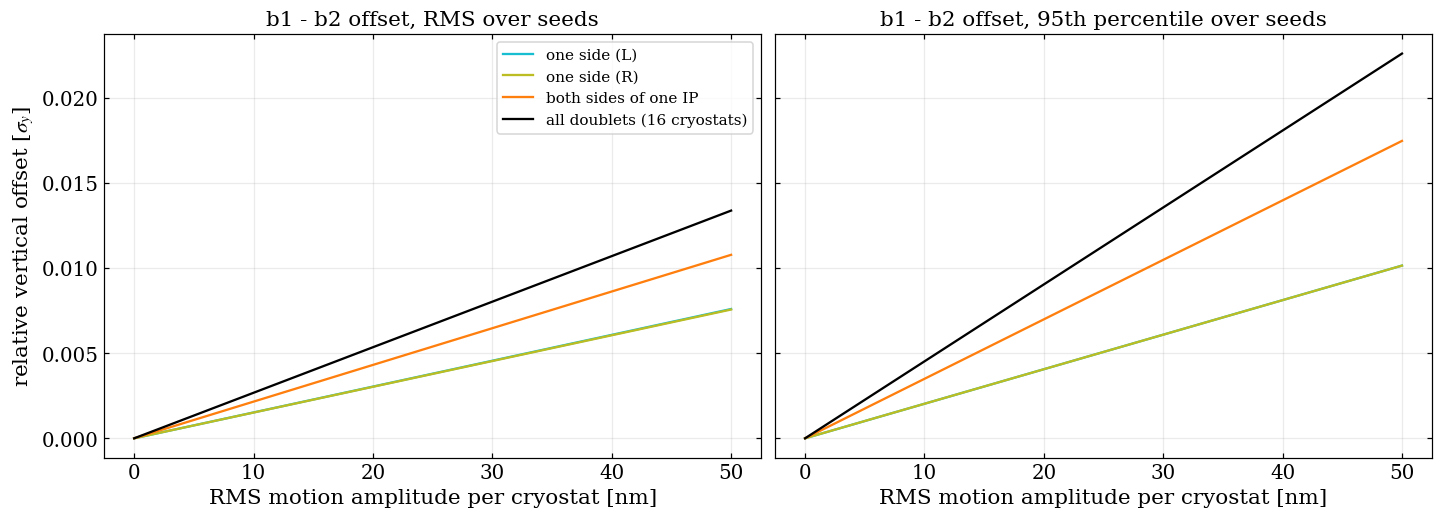

In [12]:
amplitudes = np.linspace(0, 50, 51)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True, layout='constrained')
for ax, stat, name in zip(axes, (lambda x: np.sqrt(np.mean(x**2)), lambda x: np.quantile(x, 0.95)), ('RMS over seeds', '95th percentile over seeds')):
    for case, color in zip(CASE_LABELS, ('tab:cyan', 'tab:olive', 'tab:orange', 'k')):
        kappa = stat(local[local.case == case]['diff_rms_sigma'].to_numpy())/A_REF_NM
        ax.plot(amplitudes, kappa*amplitudes, color=color, label=CASE_LABELS[case].replace('\n', ' '))
    ax.set_xlabel('RMS motion amplitude per cryostat [nm]'); ax.set_title(f'b1 - b2 offset, {name}')
    ax.grid(alpha=0.25)
axes[0].set_ylabel(r'relative vertical offset [$\sigma_y$]'); axes[0].legend()
fig.savefig(FIGURE_DIR/'relative_offset_vs_amplitude.png'); plt.show()

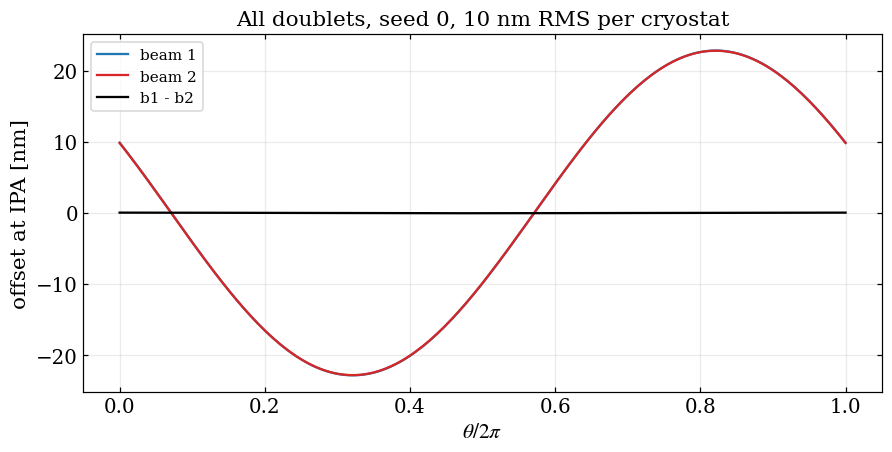

In [13]:
# time dependence for one random phase set, all doublets moving, at IPA
seed, i_ip = 0, 0
theta = np.linspace(0, 2*np.pi, 200)
shifts = np.sqrt(2.0)*A_REF_NM*np.cos(theta[:, None] + random_phases(seed)[None, :])      # nm, (theta, cryostats)
y1, y2 = shifts @ R1[i_ip], shifts @ R2[i_ip]
fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
ax.plot(theta/(2*np.pi), y1, color='tab:blue', label='beam 1'); ax.plot(theta/(2*np.pi), y2, color='tab:red', label='beam 2')
ax.plot(theta/(2*np.pi), y1 - y2, 'k', label='b1 - b2')
ax.set_xlabel(r'$\theta/2\pi$'); ax.set_ylabel('offset at IPA [nm]'); ax.grid(alpha=0.25); ax.legend()
ax.set_title(f'All doublets, seed {seed}, {A_REF_NM:g} nm RMS per cryostat')
fig.savefig(FIGURE_DIR/'time_dependence_ipa.png'); plt.show()

## 9. Headline numbers: offset of each beam and relative offset at the IP

Pooled over the 4 IPs and all seeds (`all_doublets`: the 4 IPs pooled too), at the reference amplitude. "Relative offset" = $y_{b1}-y_{b2}$ at the IP marker.

In [14]:
rows = []
for case in CASE_LABELS:
    g = local[local.case == case]
    row = {'case': case.replace('_', ' ')}
    for quantity, label in (('b1', 'b1'), ('b2', 'b2'), ('diff', 'b1-b2')):
        v = g[f'{quantity}_rms_nm'].to_numpy()
        row[f'{label} median [nm]'] = np.median(v); row[f'{label} 95% [nm]'] = np.quantile(v, 0.95)
    row['b1-b2 median [sigma_y]'] = np.median(g['diff_rms_sigma']); row['b1-b2 95% [sigma_y]'] = np.quantile(g['diff_rms_sigma'], 0.95)
    rows.append(row)
headline = pd.DataFrame(rows).set_index('case')
headline.to_csv(OUTPUT_DIR/'headline_offsets.csv')
print(f'RMS over the temporal phase, {A_REF_NM:g} nm RMS per cryostat, {N_SEEDS} seeds')
display(headline.round(3))

RMS over the temporal phase, 10 nm RMS per cryostat, 2000 seeds


,b1 median [nm],b1 95% [nm],b2 median [nm],b2 95% [nm],b1-b2 median [nm],b1-b2 95% [nm],b1-b2 median [sigma_y],b1-b2 95% [sigma_y]
case,,,,,,,,
one side L,7.743,9.790,7.809,9.880,0.066,0.089,0.002,0.002
one side R,7.803,9.877,7.737,9.788,0.066,0.089,0.002,0.002
both sides,10.233,17.300,10.234,17.295,0.085,0.154,0.002,0.003
all doublets,11.943,23.197,11.924,23.201,0.101,0.199,0.002,0.005


## 10. Closed orbit of both beams around every IP (direct Twiss)

One representative random-phase set: the seed whose `all_doublets` b1 offset at IPA is closest to the median, at the temporal phase where that offset peaks. The same phases and temporal phase are used for every IP and case, and the displacements are applied to both rings. For IP X, the cases `one_side_L/R` and `both_sides` move only the doublet of IP X; `all_doublets` is the same configuration seen at each IP. The z axis is the physical frame (b2 is mirrored). The lower row is the relative vertical offset (distance) between the two beams at the same z, compared only at boundaries that coincide physically.

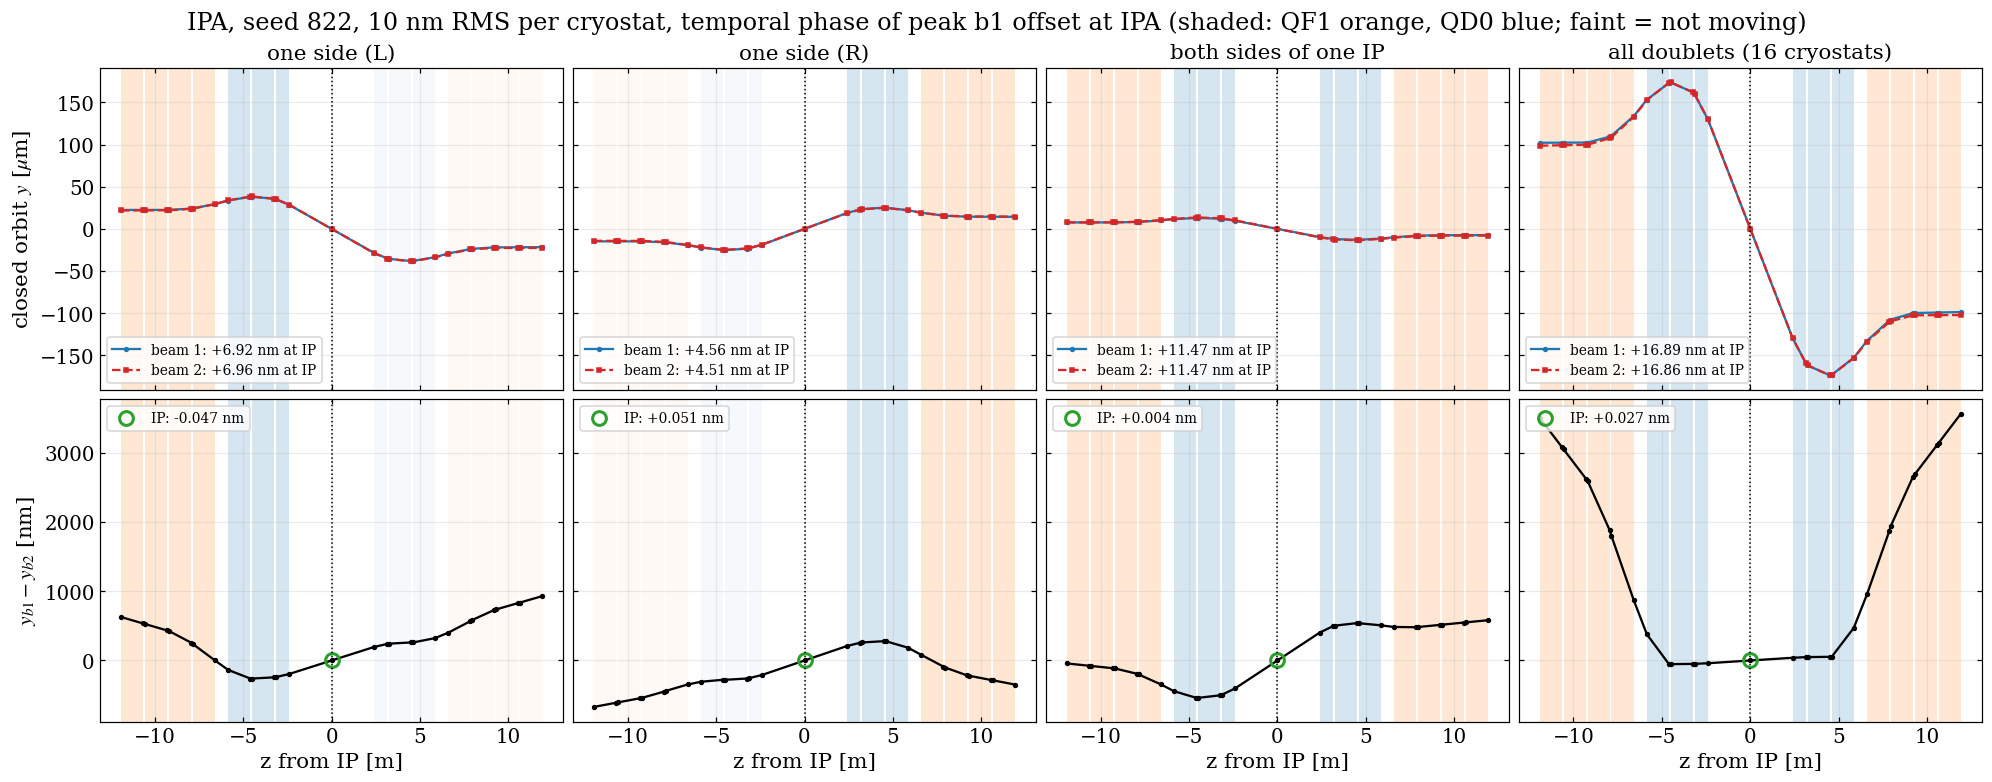

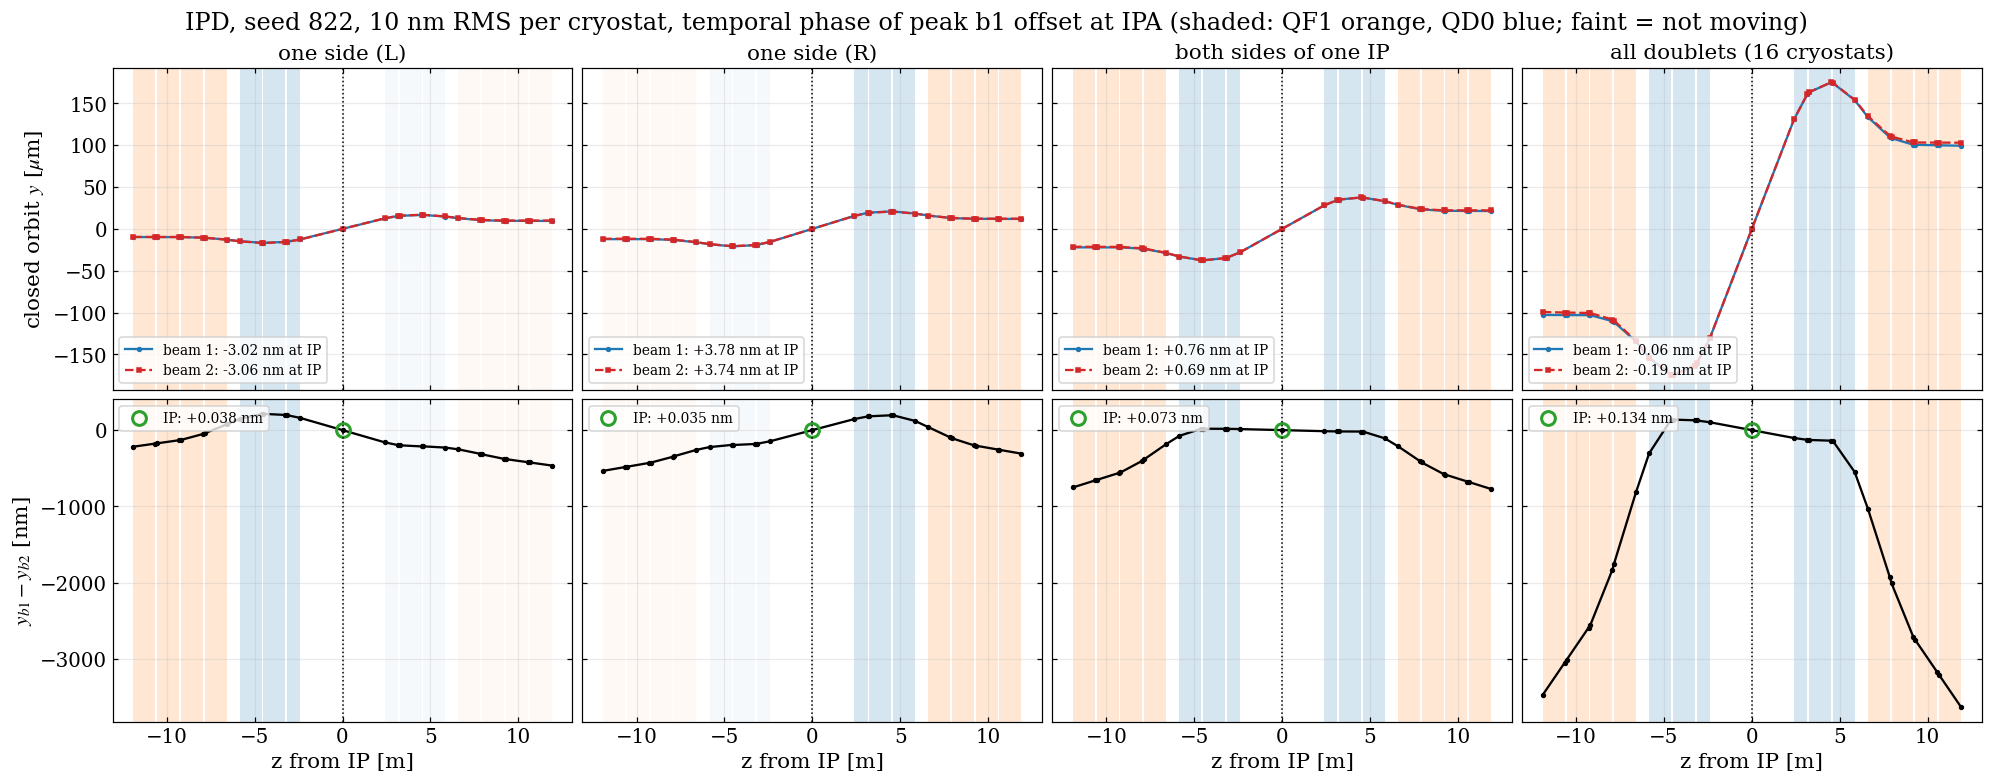

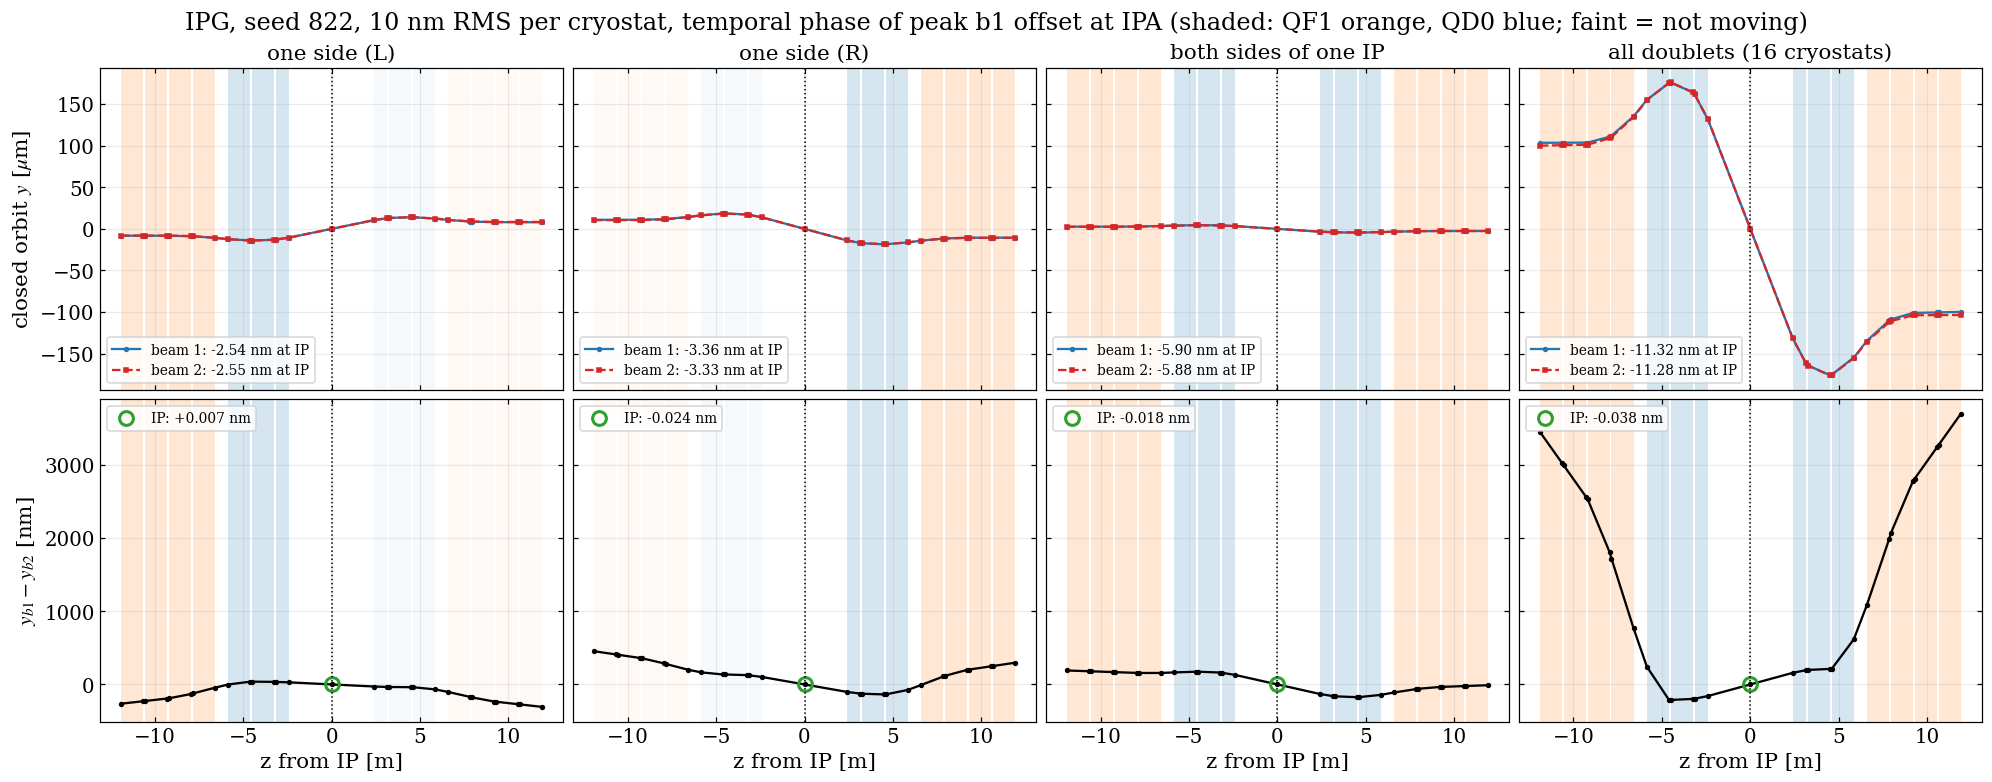

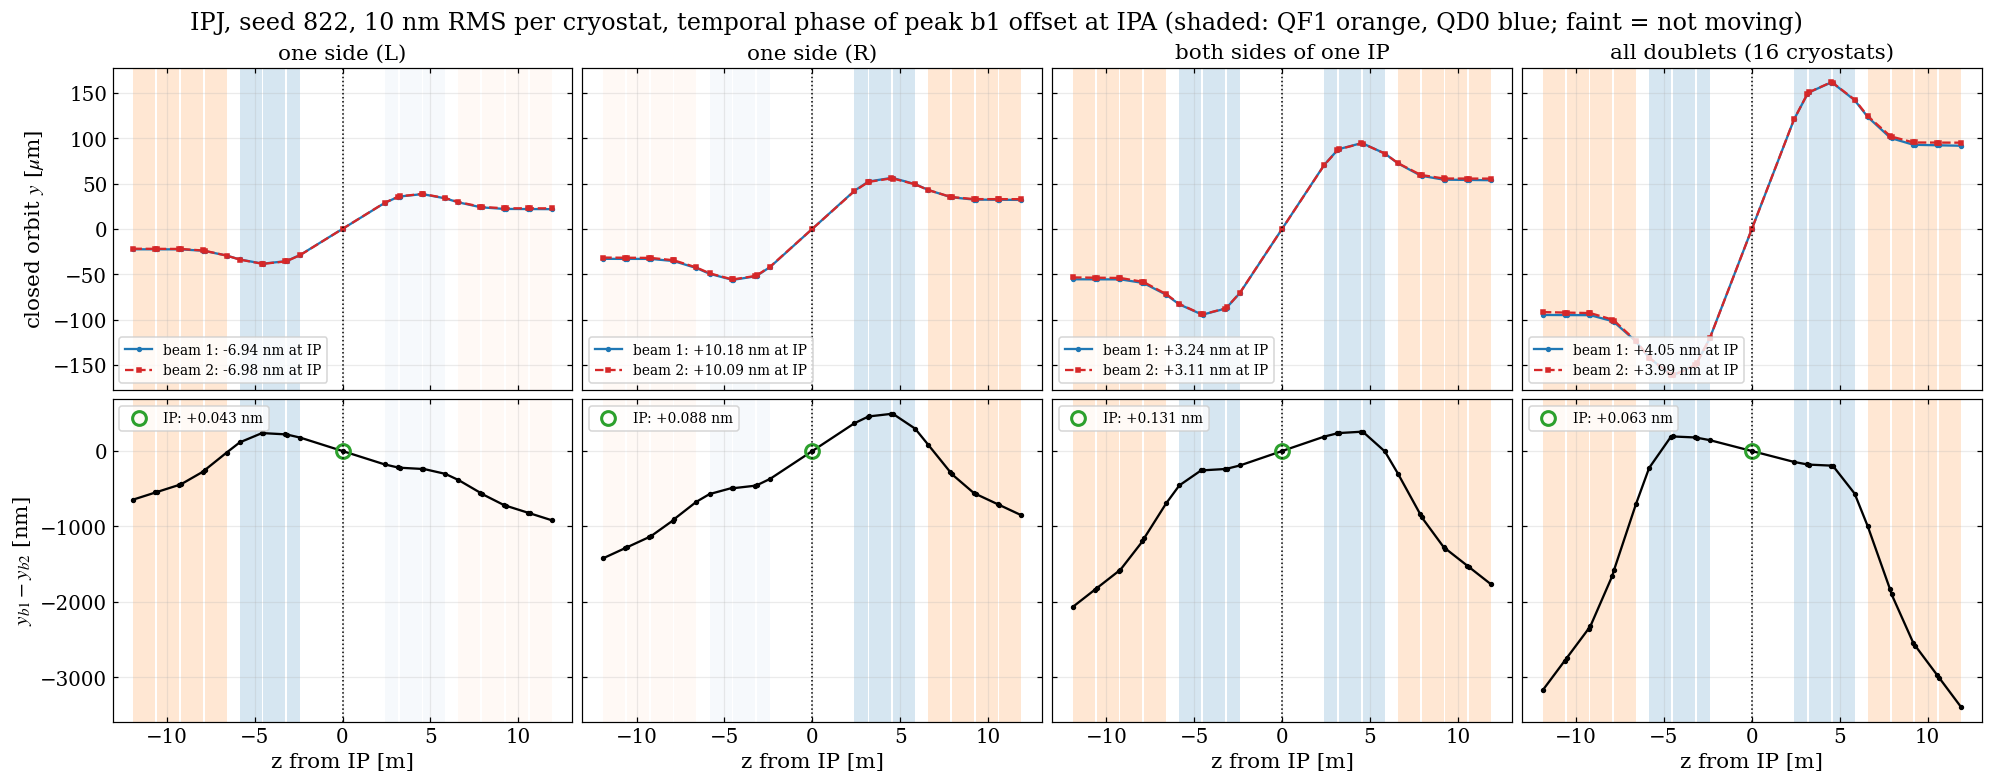

b1_nm                          b2_nm                         \
ip               ipa    ipd     ipg     ipj     ipa    ipd     ipg     ipj   
case                                                                         
one_side_L     6.916 -3.018  -2.542  -6.939   6.963 -3.057  -2.549  -6.982   
one_side_R     4.558  3.777  -3.357  10.181   4.507  3.742  -3.332  10.092   
both_sides    11.474  0.759  -5.898   3.242  11.470  0.686  -5.881   3.110   
all_doublets  16.892 -0.057 -11.316   4.055  16.864 -0.191 -11.277   3.992   

             b1-b2_nm                       
ip                ipa    ipd    ipg    ipj  
case                                        
one_side_L     -0.047  0.038  0.007  0.043  
one_side_R      0.051  0.035 -0.024  0.088  
both_sides      0.004  0.073 -0.018  0.131  
all_doublets    0.027  0.134 -0.038  0.063

In [15]:
WINDOW = 15.0
CASES_PLOT = ('one_side_L', 'one_side_R', 'both_sides', 'all_doublets')
all_mask = active_mask('all_doublets', None)
S_all = phasors[:, all_mask] @ R1[0, all_mask]
seed_plot = int(seeds[np.argmin(np.abs(np.abs(S_all) - np.median(np.abs(S_all))))])
theta_plot = -np.angle(S_all[seed_plot])
shifts_full = np.sqrt(2.0)*A_REF_NM*1e-9*np.cos(theta_plot + random_phases(seed_plot))     # m, per cryostat

def orbit_window(beam, ip):
    twiss = lines[beam].twiss(method='4d')
    s = np.asarray(twiss.s, float); y = np.asarray(twiss.y, float); circumference = lines[beam].get_length()
    s_ip = float(s[np.asarray(twiss.name, str) == ip][0])
    z = (s - s_ip + circumference/2) % circumference - circumference/2
    if beam == 'b2':
        z = -z
    keep = np.abs(z) <= WINDOW
    order = np.argsort(z[keep], kind='stable')
    return z[keep][order], y[keep][order]

def common(orbit_case):
    (z1, y1), (z2, y2) = orbit_case['b1'], orbit_case['b2']
    k1 = {round(float(z), 6): float(y) for z, y in zip(z1, y1)}; k2 = {round(float(z), 6): float(y) for z, y in zip(z2, y2)}
    zc = np.array(sorted(set(k1) & set(k2)))
    return zc, np.array([k1[z] for z in zc]), np.array([k2[z] for z in zc])

def quadrupole_spans(ip):
    names = np.asarray(tables['b1'].name, str); s = np.asarray(tables['b1'].s, float); circumference = lines['b1'].get_length()
    spans = []
    for name, (ip_g, side, magnet) in doublet_cryostats('b1').items():
        if ip_g == ip:
            d0 = (float(s[names == name][0]) - float(s[names == ip][0]) + circumference/2) % circumference - circumference/2
            spans.append((d0, d0 + float(lines['b1'][name].length), side, magnet))
    return spans

ip_summary = []
for ip in IP_NAMES:
    orbit = {}
    for case in CASES_PLOT:
        mask = active_mask(case, None if case == 'all_doublets' else ip)
        for beam in lines:
            for cryostat, value, on in zip(CRYOSTATS, shifts_full, mask):
                set_shift(beam, cryostat, value if on else 0.0)
        orbit[case] = {beam: orbit_window(beam, ip) for beam in lines}
        for beam in lines:
            for cryostat in CRYOSTATS:
                set_shift(beam, cryostat, 0.0)
    fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharex=True, sharey='row', layout='constrained')
    spans = quadrupole_spans(ip)
    for col, case in enumerate(CASES_PLOT):
        zc, y1, y2 = common(orbit[case]); i0 = int(np.argmin(np.abs(zc)))
        ax_top, ax_bot = axes[0, col], axes[1, col]
        ax_top.plot(zc, 1e6*y1, '-o', ms=2.5, color='tab:blue', label=f'beam 1: {1e9*y1[i0]:+.2f} nm at IP')
        ax_top.plot(zc, 1e6*y2, '--s', ms=2.5, color='tab:red', label=f'beam 2: {1e9*y2[i0]:+.2f} nm at IP')
        ax_bot.plot(zc, 1e9*(y1 - y2), '-o', ms=2.5, color='k')
        ax_bot.plot(zc[i0], 1e9*(y1[i0] - y2[i0]), 'o', ms=9, mfc='none', mec='tab:green', mew=2, label=f'IP: {1e9*(y1[i0]-y2[i0]):+.3f} nm')
        for a, b, side, magnet in spans:
            active = case in ('both_sides', 'all_doublets') or case == f'one_side_{side}'
            for ax in (ax_top, ax_bot):
                ax.axvspan(a, b, color='tab:orange' if magnet == 'QF1' else 'tab:blue', alpha=0.18 if active else 0.04, lw=0)
        for ax in (ax_top, ax_bot):
            ax.axvline(0, color='k', ls=':', lw=1); ax.grid(alpha=0.25)
        ax_top.set_title(CASE_LABELS[case].replace('\n', ' ')); ax_bot.set_xlabel('z from IP [m]')
        ax_top.legend(loc='lower left', fontsize=9); ax_bot.legend(loc='upper left', fontsize=9)
        ip_summary.append({'ip': ip, 'case': case, 'b1_nm': 1e9*y1[i0], 'b2_nm': 1e9*y2[i0], 'b1-b2_nm': 1e9*(y1[i0] - y2[i0])})
    axes[0, 0].set_ylabel(r'closed orbit $y$ [$\mu$m]'); axes[1, 0].set_ylabel(r'$y_{b1}-y_{b2}$ [nm]')
    fig.suptitle(f'{ip.upper()}, seed {seed_plot}, {A_REF_NM:g} nm RMS per cryostat, temporal phase of peak b1 offset at IPA (shaded: QF1 orange, QD0 blue; faint = not moving)')
    fig.savefig(FIGURE_DIR/f'closed_orbit_around_{ip}.png'); plt.show()

ip_summary = pd.DataFrame(ip_summary)
ip_summary.to_csv(OUTPUT_DIR/'closed_orbit_ip_offsets_representative_seed.csv', index=False)
display(ip_summary.pivot(index='case', columns='ip', values=['b1_nm', 'b2_nm', 'b1-b2_nm']).reindex(list(CASES_PLOT)).round(3))

## 11. Relative IP offset b1 - b2 versus amplitude, with seed spread (direct closed-orbit scan)

Same plot and definitions as `ip_y_offset_seed_spread.pdf` of the ground-motion seed study, but for the **relative vertical offset of the two beams at the IP**.

The data come from `run_direct_scan.py`, which computes the closed orbit of both rings with Twiss for every (case, IP, amplitude, seed, temporal phase), in parallel. The linear response model of section 5 is **not** used here. It is accurate near 10 nm, but the relative offset is a small difference of two large numbers, and at 50-200 nm the sextupole feed-down of the mm-scale orbit breaks the mirror symmetry between the two rings (see the comparison below).

* 5 temporal phases $\theta = 2\pi k/5$. The y axis is the maximum $|y_{b1}-y_{b2}|$ over these temporal phases.
* Curve = median over seeds, band = 16-84% over seeds, 40 seeds (42-81) per case.
* Limits at 0.1, 0.2, 0.3 $\sigma_y^*$. The box lists the amplitude at which the median curve crosses each limit.
* Cases: only one side of the IP moves (L or R), both sides of the IP move, or all 16 doublet cryostats move. For the first three the IP shown is the IP whose doublet moves. `all doublets` is observed at each IP.

In [16]:
SCAN_DIR = OUTPUT_DIR/'direct_scan'
scan_files = sorted(SCAN_DIR.glob('amplitude_*nm.csv'))
assert scan_files, 'run run_direct_scan.py first (python run_direct_scan.py 8)'
scan = pd.concat([pd.read_csv(f) for f in scan_files], ignore_index=True)
print(f'{len(scan_files)} amplitudes, {scan.seed.nunique()} seeds, converged: {scan.converged.mean():.4f}')
scan = scan[scan.converged]
zero = scan[np.isclose(scan.amplitude_rms_nm, scan.amplitude_rms_nm.min())].assign(amplitude_rms_nm=0.0, max_abs_b1_nm=0.0, max_abs_b2_nm=0.0, max_abs_relative_nm=0.0)
scan = pd.concat([zero, scan], ignore_index=True)
spread = scan.rename(columns={'max_abs_relative_nm': 'max_abs_relative_offset_nm'})
SPREAD_CASES = ('one_side_L', 'one_side_R', 'both_sides', 'all_doublets')
TEMPORAL_PHASES = np.linspace(0.0, 2.0*np.pi, 5, endpoint=False)
phases_spread = np.array([random_phases(int(seed)) for seed in sorted(scan.seed.unique())])
cos_theta = np.cos(TEMPORAL_PHASES[:, None, None] + phases_spread[None, :, :])               # (theta, seeds, cryostats)

def linear_max_offset_nm(case, observed_ip, amplitude_nm, response_vector):
    # linear-model prediction: maximum over the temporal phases, per seed [nm]
    mask = active_mask(case, observed_ip)
    return 1e9*np.max(np.abs(np.sqrt(2.0)*amplitude_nm*1e-9*(cos_theta[:, :, mask] @ response_vector[mask])), axis=0)

11 amplitudes, 40 seeds, converged: 1.0000


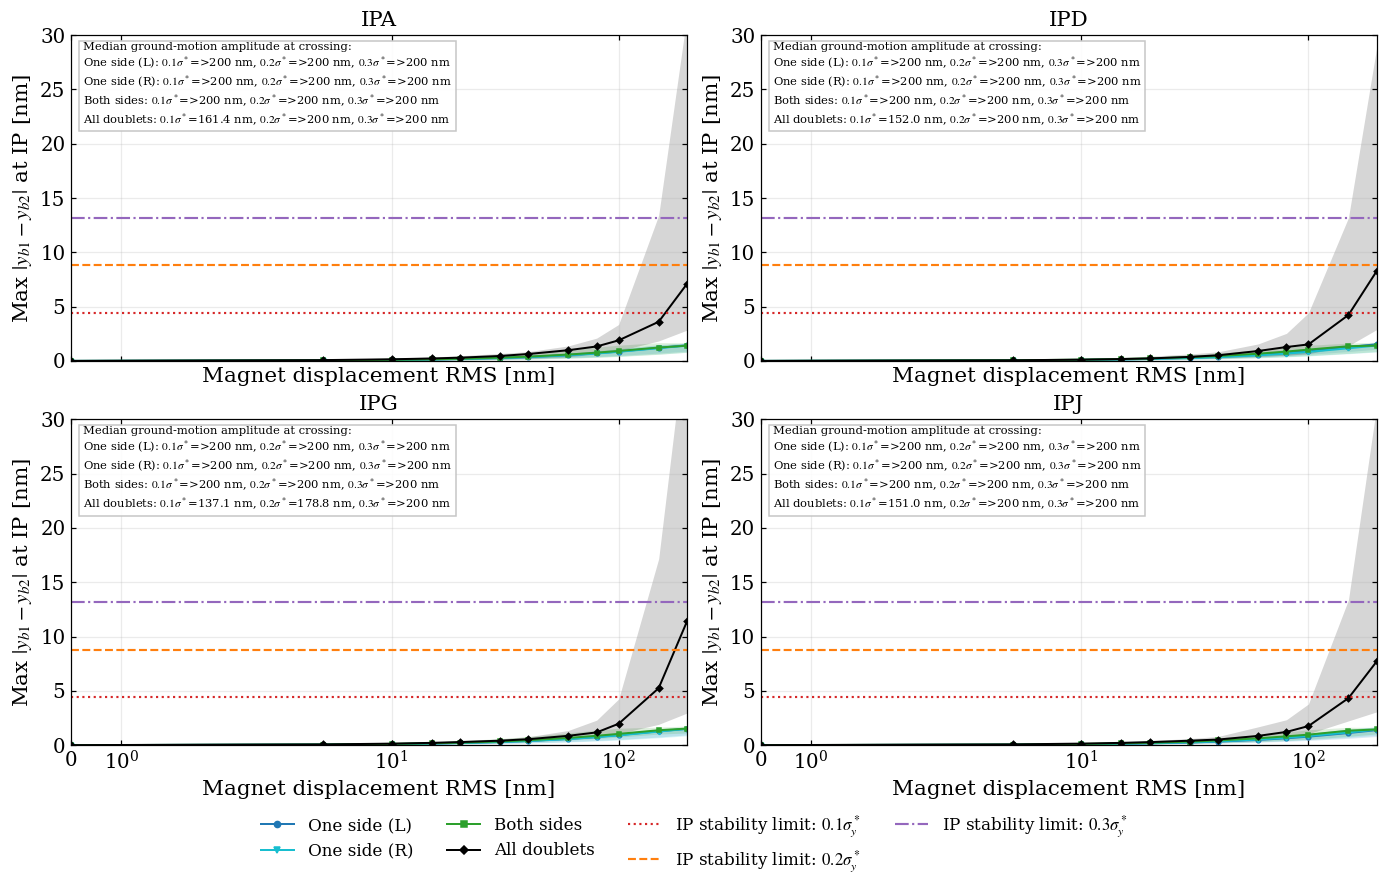

In [17]:
SPREAD_LABELS = {'one_side_L': 'One side (L)', 'one_side_R': 'One side (R)', 'both_sides': 'Both sides', 'all_doublets': 'All doublets'}
SPREAD_STYLES = {'one_side_L': ('tab:blue', 'o'), 'one_side_R': ('tab:cyan', 'v'), 'both_sides': ('tab:green', 's'), 'all_doublets': ('black', 'D')}
STABILITY_LIMITS = ((0.1, 'tab:red', ':'), (0.2, 'tab:orange', '--'), (0.3, 'tab:purple', '-.'))

def first_median_crossing(x, y, threshold):
    x = np.asarray(x, float); y = np.asarray(y, float)
    valid = np.isfinite(x) & np.isfinite(y); x, y = x[valid], y[valid]
    order = np.argsort(x); x, y = x[order], y[order]
    reached = np.flatnonzero(y >= threshold)
    if len(reached) == 0:
        return np.inf
    index = reached[0]
    if index == 0:
        return x[0]
    x0, x1, y0, y1 = x[index - 1], x[index], y[index - 1], y[index]
    return x1 if y1 == y0 else x0 + (threshold - y0)*(x1 - x0)/(y1 - y0)

def seed_band(frame, column):
    grouped = frame.groupby('amplitude_rms_nm')[column]
    x = np.asarray(sorted(frame.amplitude_rms_nm.unique()), float)
    return x, grouped.median().reindex(x).to_numpy(float), grouped.quantile(0.16).reindex(x).to_numpy(float), grouped.quantile(0.84).reindex(x).to_numpy(float)

def plot_relative_offset_spread(data, ylim=(0, 30)):
    fig, axes = plt.subplots(2, 2, figsize=(12.5, 8), sharex=True, layout='constrained')
    for ax, ip in zip(axes.flat, IP_NAMES):
        sigma_nm = 1e9*sigma_y_diff_m[IP_NAMES.index(ip)]
        curves = {}
        for case in SPREAD_CASES:
            d = data[(data.case == case) & (data.observed_ip == ip)]
            x, median, low, high = seed_band(d, 'max_abs_relative_offset_nm')
            color, marker = SPREAD_STYLES[case]
            ax.plot(x, median, color=color, marker=marker, ms=3, lw=1.3)
            ax.fill_between(x, low, high, color=color, alpha=0.16, linewidth=0)
            curves[case] = (x, median)
        for fraction, color, linestyle in STABILITY_LIMITS:
            ax.axhline(fraction*sigma_nm, color=color, ls=linestyle, lw=1.4)
        lines_text = ['Median ground-motion amplitude at crossing:']
        for case, (x, median) in curves.items():
            parts = []
            for fraction, _, _ in STABILITY_LIMITS:
                crossing = first_median_crossing(x, median, fraction*sigma_nm)
                parts.append(rf'${fraction:.1f}\sigma^*$=' + (f'>{x.max():g} nm' if np.isinf(crossing) else f'{crossing:.1f} nm'))
            lines_text.append(f'{SPREAD_LABELS[case]}: ' + ', '.join(parts))
        ax.text(0.02, 0.98, '\n'.join(lines_text), transform=ax.transAxes, ha='left', va='top', fontsize=7.5,
                bbox=dict(facecolor='white', edgecolor='0.75', alpha=0.88, pad=2.5))
        ax.set_title(ip.upper()); ax.set_xscale('symlog', linthresh=5); ax.set_xlim(0, 200); ax.set_ylim(*ylim)
        ax.set_xlabel('Magnet displacement RMS [nm]'); ax.set_ylabel(r'Max $|y_{b1}-y_{b2}|$ at IP [nm]')
        ax.grid(True, which='both', alpha=0.25)
    from matplotlib.lines import Line2D
    handles = [Line2D([0], [0], color=SPREAD_STYLES[c][0], marker=SPREAD_STYLES[c][1], ms=4, lw=1.3) for c in SPREAD_CASES] + \
              [Line2D([0], [0], color=c, ls=l, lw=1.4) for _, c, l in STABILITY_LIMITS]
    labels = [SPREAD_LABELS[c] for c in SPREAD_CASES] + [rf'IP stability limit: ${f:.1f}\sigma_y^*$' for f, _, _ in STABILITY_LIMITS]
    fig.legend(handles, labels, loc='outside lower center', ncols=4, frameon=False, fontsize=11)
    return fig, axes

fig, axes = plot_relative_offset_spread(spread)
fig.savefig(FIGURE_DIR/'ip_relative_y_offset_seed_spread.pdf'); fig.savefig(FIGURE_DIR/'ip_relative_y_offset_seed_spread.png'); plt.show()

### Direct scan versus the linear model (relative offset, all doublets, median over seeds)

Dashed = linear response prediction with the same seeds and temporal phases. Solid = direct closed orbit.

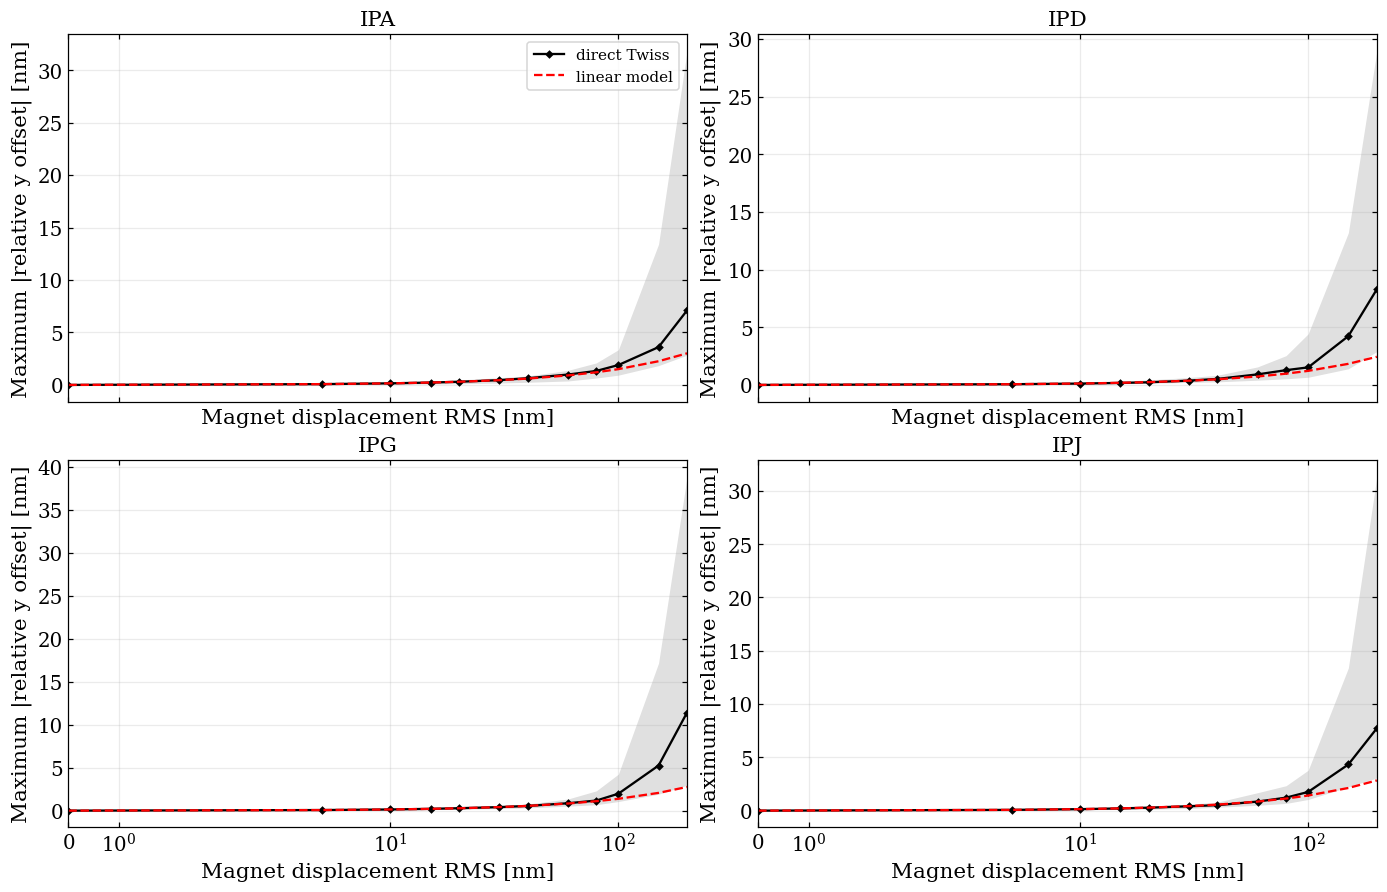

,ip,A_rms_nm,direct median [nm],linear median [nm]
0,ipa,10.0,0.151,0.151
1,ipa,200.0,7.101,3.011
2,ipd,10.0,0.117,0.122
3,ipd,200.0,8.289,2.438
4,ipg,10.0,0.138,0.138
5,ipg,200.0,11.409,2.754
6,ipj,10.0,0.141,0.142
7,ipj,200.0,7.722,2.836


In [18]:
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8), sharex=True, layout='constrained')
rows = []
for k, (ax, ip) in enumerate(zip(axes.flat, IP_NAMES)):
    d = spread[(spread.case == 'all_doublets') & (spread.observed_ip == ip)]
    x, median, low, high = seed_band(d, 'max_abs_relative_offset_nm')
    ax.plot(x, median, 'k-D', ms=3, label='direct Twiss'); ax.fill_between(x, low, high, color='k', alpha=0.12, lw=0)
    lin = np.array([np.median(linear_max_offset_nm('all_doublets', ip, a, R1[k] - R2[k])) for a in x])
    ax.plot(x, lin, 'r--', label='linear model')
    for a in (10.0, 50.0, 200.0):
        if a in x:
            rows.append({'ip': ip, 'A_rms_nm': a, 'direct median [nm]': median[list(x).index(a)], 'linear median [nm]': lin[list(x).index(a)]})
    ax.set_title(ip.upper()); ax.set_xscale('symlog', linthresh=5); ax.set_xlim(0, 200); ax.grid(True, which='both', alpha=0.25)
    ax.set_xlabel('Magnet displacement RMS [nm]'); ax.set_ylabel(r'Maximum |relative y offset| [nm]')
axes[0, 0].legend()
fig.savefig(FIGURE_DIR/'relative_offset_direct_vs_linear.png'); plt.show()
display(pd.DataFrame(rows).round(3))

## 12. Check against the ground-motion seed study: absolute offset of each beam

The old `final_doublets_rigid_magnets` scenario moves the 16 physical cryostats (key `copy<N>:<side>:<QF1|QD0>`, one random phase each), the same as `all_doublets` here, but on a single ring (LCC 106 line, one beam). Below, the maximum $|y|$ offset at each IP (same definition, 5 temporal phases, direct closed orbit) of **each beam** in this study is overlaid on the old curve. The random phases are drawn differently, so only the distributions can agree, not seed by seed.

/Users/skostogl/Documents/workspace/workspace_2025/python_installation/miniforge3/envs/xsuite_env/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/skostogl/Documents/workspace/workspace_2025/python_installation/miniforge3/envs/xsuite_env/lib/python3.11/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/Users/skostogl/Documents/workspace/workspace_2025/python_installation/miniforge3/envs/xsuite_env/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/skostogl/Documents/workspace/workspace_2025/python_installation/miniforge3/envs/xsuite_env/lib/python3.11/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


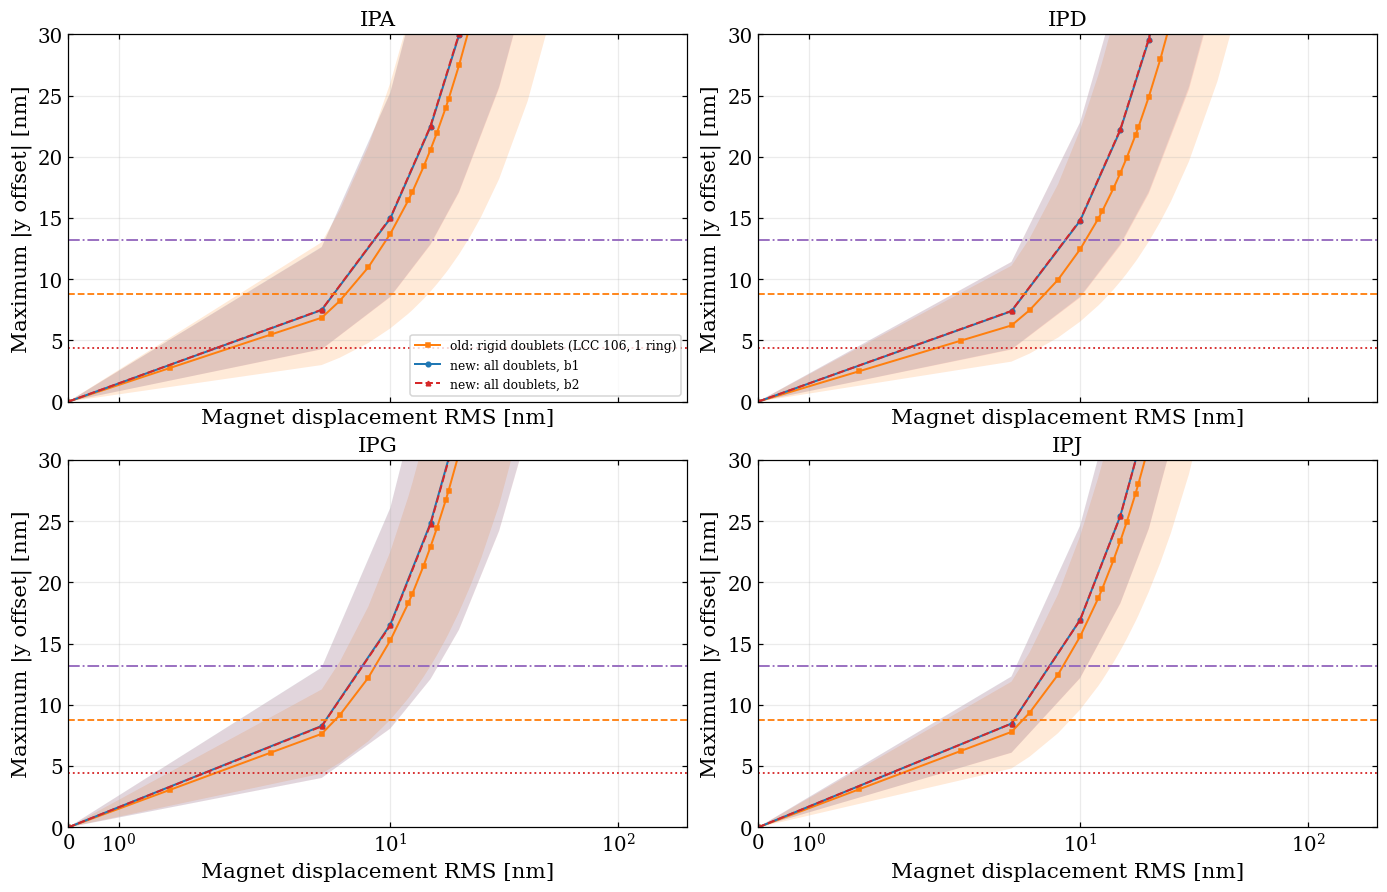

,ip,beam,A_rms_nm,new median [nm],old median [nm],new/old
0,ipa,b1,10.0,14.97,13.71,1.09
1,ipa,b1,20.0,29.92,27.46,1.09
2,ipa,b1,40.0,59.79,55.20,1.08
3,ipa,b1,100.0,148.81,NaN,NaN
4,ipa,b1,200.0,296.90,NaN,NaN
5,ipa,b2,10.0,15.01,13.71,1.09
6,ipa,b2,20.0,30.03,27.46,1.09
7,ipa,b2,40.0,60.11,55.20,1.09
8,ipa,b2,100.0,151.22,NaN,NaN
9,ipa,b2,200.0,308.31,NaN,NaN


In [19]:
OLD_SUMMARY = Path('/Users/skostogl/Documents/workspace/workspace_2026/FCC/09_2026/ground_motion_seed_scan/results/seed_summary.csv')
old = pd.read_csv(OLD_SUMMARY, usecols=['scenario', 'amplitude_rms_nm', 'seed'] + [f'{ip}_offset_y_m_phase_max_abs' for ip in IP_NAMES])
old = old[old.scenario == 'final_doublets_rigid_magnets']
all_doublets = scan[scan.case == 'all_doublets']

fig, axes = plt.subplots(2, 2, figsize=(12.5, 8), sharex=True, layout='constrained')
comparison = []
for ax, ip in zip(axes.flat, IP_NAMES):
    sigma_nm = 1e9*sigma_y_m['b1'][IP_NAMES.index(ip)]
    x, med, lo, hi = seed_band(old.assign(v=1e9*old[f'{ip}_offset_y_m_phase_max_abs']), 'v')
    ax.plot(x, med, color='tab:orange', marker='s', ms=3, lw=1.3, label='old: rigid doublets (LCC 106, 1 ring)'); ax.fill_between(x, lo, hi, color='tab:orange', alpha=0.16, lw=0)
    for beam, color, marker, ls in (('b1', 'tab:blue', 'o', '-'), ('b2', 'tab:red', '^', '--')):
        x, med_new, lo, hi = seed_band(all_doublets[all_doublets.observed_ip == ip], f'max_abs_{beam}_nm')
        ax.plot(x, med_new, color=color, marker=marker, ms=3, lw=1.3, ls=ls, label=f'new: all doublets, {beam}'); ax.fill_between(x, lo, hi, color=color, alpha=0.12, lw=0)
        for amplitude in (10.0, 20.0, 40.0, 100.0, 200.0):
            if amplitude in x:
                comparison.append({'ip': ip, 'beam': beam, 'A_rms_nm': amplitude, 'new median [nm]': med_new[list(x).index(amplitude)],
                                   'old median [nm]': float(np.median(1e9*old[np.isclose(old.amplitude_rms_nm, amplitude)][f'{ip}_offset_y_m_phase_max_abs']))})
    for fraction, color, linestyle in STABILITY_LIMITS:
        ax.axhline(fraction*sigma_nm, color=color, ls=linestyle, lw=1.2)
    ax.set_title(ip.upper()); ax.set_xscale('symlog', linthresh=5); ax.set_xlim(0, 200); ax.set_ylim(0, 30)
    ax.set_xlabel('Magnet displacement RMS [nm]'); ax.set_ylabel('Maximum |y offset| [nm]'); ax.grid(True, which='both', alpha=0.25)
axes[0, 0].legend(loc='lower right', fontsize=8)
fig.savefig(FIGURE_DIR/'ip_y_offset_new_vs_old.pdf'); fig.savefig(FIGURE_DIR/'ip_y_offset_new_vs_old.png'); plt.show()
comparison = pd.DataFrame(comparison)
comparison['new/old'] = comparison['new median [nm]']/comparison['old median [nm]']
display(comparison.round(2))